# ML 05 - Regression Analysis: Estimating Freight Cost per Shipment

**Objective:** predict the **freight cost (USD)** of a health-commodity shipment from information available when the shipment is planned (weight, quantity, value, shipment mode, destination, route, product group), and quantify *how much each driver matters* (e.g. the cost elasticity of weight). This supports logistics budgeting and quote validation.

**Dataset:** USAID/PEPFAR *Supply Chain Shipment Pricing Data* (SCMS Delivery History): 10,324 shipment lines, 2006-2015 (public, no login). Same source as project `03_classification_model`, different question.

**Approach**
1. Inferential model: **OLS** (statsmodels) on log-cost with full assumption diagnostics, robust (HC3) confidence intervals, VIF, influential points.
2. Predictive comparison: baselines vs OLS vs Ridge / Lasso / ElasticNet vs Random Forest vs Gradient Boosting.
3. Validation: **GroupKFold by shipment** (lines of the same shipment must never be in both train and validation), then a final **chronological hold-out** (newest 20%).

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.simplefilter("ignore")   # statsmodels re-enables some warnings on import
sns.set_theme(style="whitegrid")
OUT = Path("."); SEED = 42
RAW = pd.read_csv("SCMS_Delivery_History_Dataset.csv", encoding="utf-8-sig")
print(RAW.shape)

(10324, 33)


## 1. Target and data audit
`Freight Cost (USD)` and `Weight (Kilograms)` are mixed numeric/text columns: text such as *"Freight Included in Commodity Cost"*, *"Invoiced Separately"*, *"Weight Captured Separately"* or *"See DN-304 (ID#:10589)"* means the value is **not recorded on that line**. Those lines are excluded - this is a selection effect that is discussed in the limitations.

In [2]:
MON = {m: i + 1 for i, m in enumerate(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])}
def parse_dmy(x):
    try:
        d, m, y = str(x).split("-"); return pd.Timestamp(2000 + int(y), MON[m], int(d))
    except Exception:
        return pd.NaT
df = RAW.copy()
df["freight"] = pd.to_numeric(df["Freight Cost (USD)"], errors="coerce")
df["weight"] = pd.to_numeric(df["Weight (Kilograms)"], errors="coerce")
print("freight text placeholders:"); print(RAW.loc[df.freight.isna(), "Freight Cost (USD)"].astype(str).str.replace(r"\(ID#:\d+\)|DN-\d+|ASN-\d+|SCMS-\d+", "<ref>", regex=True).value_counts().head(6).to_string())
print("\nnumeric freight: %d | numeric weight: %d | both: %d" % (df.freight.notna().sum(), df.weight.notna().sum(), (df.freight.notna() & df.weight.notna()).sum()))
d = df[df.freight.notna() & df.weight.notna()].copy()
print("non-positive freight/weight:", int((d.freight <= 0).sum()), "/", int((d.weight <= 0).sum()))
d = d[(d.freight > 0) & (d.weight > 0)]
d["sched"] = d["Scheduled Delivery Date"].map(parse_dmy)
d["Shipment Mode"] = d["Shipment Mode"].fillna("Unknown")
d["group"] = d["ASN/DN #"].astype(str)
print("rows kept:", len(d), "| distinct shipments (ASN/DN):", d.group.nunique(), "| max lines per shipment:", d.group.value_counts().max())
print("\nFreight (USD):", d.freight.describe(percentiles=[.05, .5, .95]).round(0).to_dict())
print("Skewness raw %.1f -> log %.2f" % (d.freight.skew(), np.log(d.freight).skew()))
print("Mode mix:", d["Shipment Mode"].value_counts().to_dict())

freight text placeholders:
Freight Cost (USD)
See <ref> <ref>                       2445
Freight Included in Commodity Cost    1442
Invoiced Separately                    239

numeric freight: 6198 | numeric weight: 6372 | both: 6175
non-positive freight/weight: 0 / 1
rows kept: 6174 | distinct shipments (ASN/DN): 6174 | max lines per shipment: 1

Freight (USD): {'count': 6174.0, 'mean': 11125.0, 'std': 15831.0, 'min': 1.0, '5%': 641.0, '50%': 5887.0, '95%': 36684.0, 'max': 289653.0}
Skewness raw 4.7 -> log -0.37
Mode mix: {'Air': 4096, 'Truck': 1162, 'Air Charter': 423, 'Ocean': 282, 'Unknown': 211}


lines per shipment among kept rows: median 1, max 17


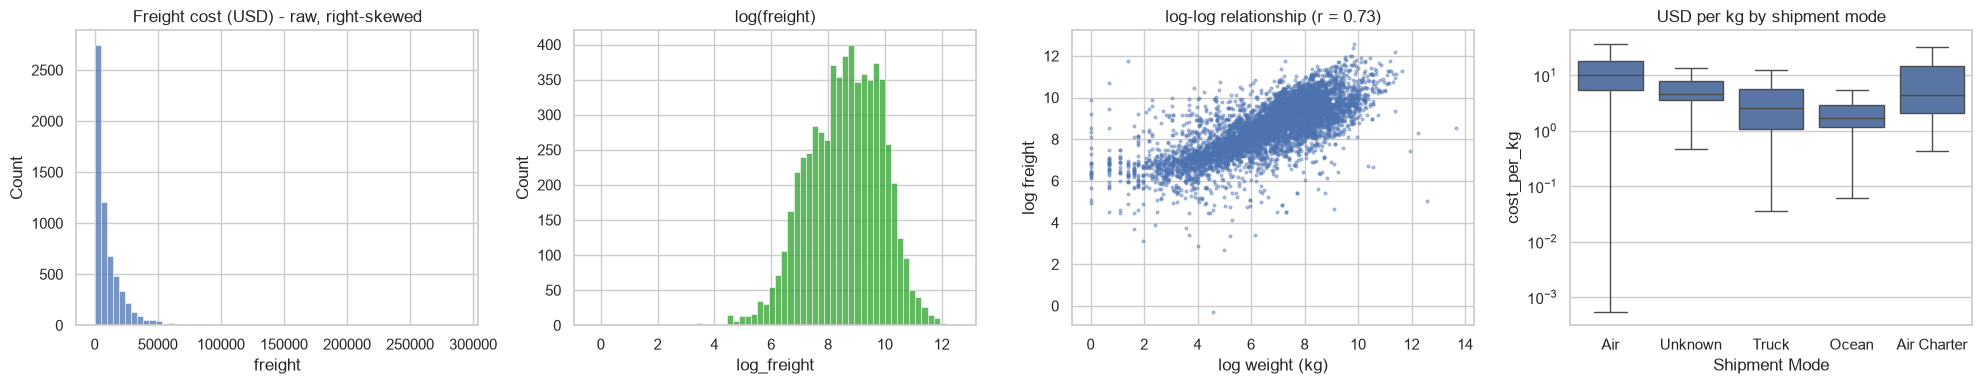

                count    50%    mean
Shipment Mode                       
Air            4096.0  10.02   33.52
Air Charter     423.0   4.32  162.33
Ocean           282.0   1.68   20.66
Truck          1162.0   2.50   14.44
Unknown         211.0   4.65   55.84


In [3]:
d["log_freight"] = np.log(d.freight)
d["log_weight"] = np.log(d.weight)
# freight/weight are recorded once per shipment (on its first line; the other lines say "See DN-xxx"), so quantity and
# value are aggregated over ALL lines of the same shipment (ASN/DN #) to describe the whole shipment
agg = RAW.groupby("ASN/DN #").agg(ship_lines=("ID", "size"), ship_value=("Line Item Value", "sum"), ship_qty=("Line Item Quantity", "sum"))
d = d.merge(agg, left_on="ASN/DN #", right_index=True, how="left")
print("lines per shipment among kept rows: median %d, max %d" % (d.ship_lines.median(), d.ship_lines.max()))
d["log_ship_qty"] = np.log(d.ship_qty.clip(lower=1))
d["log_ship_value"] = np.log(d.ship_value.clip(lower=1))
d["log_ship_lines"] = np.log(d.ship_lines)
d["year"] = d.sched.dt.year
d["cost_per_kg"] = d.freight / d.weight
d = d.sort_values(["sched", "ID"]).reset_index(drop=True)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(d.freight, bins=60, ax=ax[0]); ax[0].set_title("Freight cost (USD) - raw, right-skewed")
sns.histplot(d.log_freight, bins=60, ax=ax[1], color="tab:green"); ax[1].set_title("log(freight)")
ax[2].scatter(d.log_weight, d.log_freight, s=4, alpha=.4); ax[2].set_xlabel("log weight (kg)"); ax[2].set_ylabel("log freight"); ax[2].set_title("log-log relationship (r = %.2f)" % np.corrcoef(d.log_weight, d.log_freight)[0, 1])
sns.boxplot(data=d, x="Shipment Mode", y="cost_per_kg", ax=ax[3], showfliers=False); ax[3].set_yscale("log"); ax[3].set_title("USD per kg by shipment mode")
plt.tight_layout(); plt.savefig(OUT / "01_target_exploration.png", dpi=130); plt.show()
print(d.groupby("Shipment Mode")["cost_per_kg"].describe()[["count", "50%", "mean"]].round(2))

**Why log-log:** freight is strongly right-skewed and multiplicative (cost scales with weight), so modelling `log(freight)` on `log(weight)` gives a stable variance and a directly interpretable **elasticity** (a coefficient of 0.8 means +1% weight -> +0.8% cost).

## 2. Split
Chronological: the oldest 80% (by scheduled delivery date) is the development set (all model selection, CV, OLS); the newest 20% is held out for the final check.

In [4]:
n_dev = int(0.8 * len(d))
dev, test = d.iloc[:n_dev].copy(), d.iloc[n_dev:].copy()
print("dev: %d rows %s -> %s | test: %d rows %s -> %s" % (len(dev), dev.sched.min().date(), dev.sched.max().date(), len(test), test.sched.min().date(), test.sched.max().date()))
print("shipments shared between dev and test:", len(set(dev.group) & set(test.group)))
def lump(col, min_count):
    keep = dev[col].value_counts(); keep = set(keep[keep >= min_count].index)
    for t in (dev, test): t[col + "_g"] = np.where(t[col].isin(keep), t[col], "Other")
for c, m in [("Country", 100), ("Vendor INCO Term", 30), ("Product Group", 30), ("Shipment Mode", 30), ("Vendor", 150)]: lump(c, m)
print({c: dev[c + "_g"].nunique() for c in ["Country", "Vendor INCO Term", "Product Group", "Shipment Mode", "Vendor"]})
print("Fulfill Via is NOT used: it is perfectly collinear with INCO term (From RDC <=> 'N/A - From RDC'):", pd.crosstab(d["Fulfill Via"], d["Vendor INCO Term"] == "N/A - From RDC").values.tolist())
NUM = ["log_weight", "log_ship_qty", "log_ship_value", "log_ship_lines", "year"]
CAT = ["Shipment Mode_g", "Country_g", "Vendor INCO Term_g", "Product Group_g", "Vendor_g"]

dev: 4939 rows 2006-05-02 -> 2013-12-23 | test: 1235 rows 2013-12-23 -> 2015-08-18
shipments shared between dev and test: 0
{'Country': 14, 'Vendor INCO Term': 6, 'Product Group': 3, 'Shipment Mode': 5, 'Vendor': 7}
Fulfill Via is NOT used: it is perfectly collinear with INCO term (From RDC <=> 'N/A - From RDC'): [[2981, 0], [0, 3193]]


## 3. OLS with diagnostics (development set)
Specification: `log_freight ~ log_weight + log_ship_qty + log_ship_value + log_ship_lines + year + shipment mode + country + INCO term + product group + vendor` (quantity, value and number of lines are totals over the whole shipment). Weight, quantity and value are strongly related, so multicollinearity is checked with VIF. Standard errors are **HC3-robust** because heteroscedasticity is tested below. (The fulfilment route is left out: it is perfectly collinear with the INCO term - an earlier draft that included it produced a rank-deficient design matrix.)

In [5]:
formula = "log_freight ~ log_weight + log_ship_qty + log_ship_value + log_ship_lines + year + C(Q('Shipment Mode_g')) + C(Q('Country_g')) + C(Q('Vendor INCO Term_g')) + C(Q('Product Group_g')) + C(Q('Vendor_g'))"
ols = smf.ols(formula, data=dev).fit()
rob = ols.get_robustcov_results(cov_type="HC3")
print("n = %d | R2 = %.3f | adj. R2 = %.3f | AIC = %.0f | residual std = %.3f (log units)" % (ols.nobs, ols.rsquared, ols.rsquared_adj, ols.aic, np.sqrt(ols.scale)))
names = ols.model.exog_names
ci = pd.DataFrame(np.asarray(rob.conf_int()), index=names, columns=["ci_low", "ci_high"])
coef = pd.DataFrame({"coef": rob.params, "robust_se": rob.bse, "p_value": rob.pvalues}, index=names).join(ci)
core = coef.loc[["log_weight", "log_ship_qty", "log_ship_value", "log_ship_lines", "year"]]
print("\nContinuous drivers (HC3 robust 95% CI):"); display(core.round(4))
print("Shipment-mode effects (relative to baseline level; exp(coef)-1 = % cost difference at equal weight/quantity):")
mode = coef[coef.index.str.contains("Shipment Mode")].copy(); mode["pct_effect"] = (np.exp(mode.coef) - 1) * 100
display(mode.round(3))
coef.round(5).to_csv(OUT / "ols_coefficients.csv")

n = 4939 | R2 = 0.640 | adj. R2 = 0.638 | AIC = 11479 | residual std = 0.771 (log units)

Continuous drivers (HC3 robust 95% CI):


,coef,robust_se,p_value,ci_low,ci_high
log_weight,0.3596,0.0271,0.0000,0.3065,0.4126
log_ship_qty,0.0736,0.0300,0.0142,0.0148,0.1325
log_ship_value,0.0395,0.0231,0.0879,-0.0059,0.0848
log_ship_lines,0.0522,0.0280,0.0621,-0.0026,0.1070
year,0.0444,0.0080,0.0000,0.0286,0.0601


Shipment-mode effects (relative to baseline level; exp(coef)-1 = % cost difference at equal weight/quantity):


,coef,robust_se,p_value,ci_low,ci_high,pct_effect
C(Q('Shipment Mode_g'))[T.Air Charter],0.285,0.068,0.000,0.152,0.419,33.026
C(Q('Shipment Mode_g'))[T.Ocean],0.060,0.075,0.422,-0.087,0.207,6.193
C(Q('Shipment Mode_g'))[T.Truck],-0.411,0.042,0.000,-0.494,-0.329,-33.728
C(Q('Shipment Mode_g'))[T.Unknown],-0.217,0.052,0.000,-0.319,-0.115,-19.506


Breusch-Pagan: LM=198.3, p=1.05e-24  -> heteroscedasticity present (HC3 SEs used)
Shapiro-Wilk on residuals (n<=4000): W=0.949, p=3.34e-35 | residual skew -0.47, excess kurtosis 7.13
VIF of numeric predictors: {'log_weight': 6.03, 'log_ship_qty': 5.9, 'log_ship_value': 3.94, 'log_ship_lines': 1.08, 'year': 1.02}
Cook's D > 4/n: 250 observations (5.1%) | max Cook's D 0.094 | |studentized resid|>3: 50
Weight elasticity: full 0.360 vs without high-Cook points 0.445


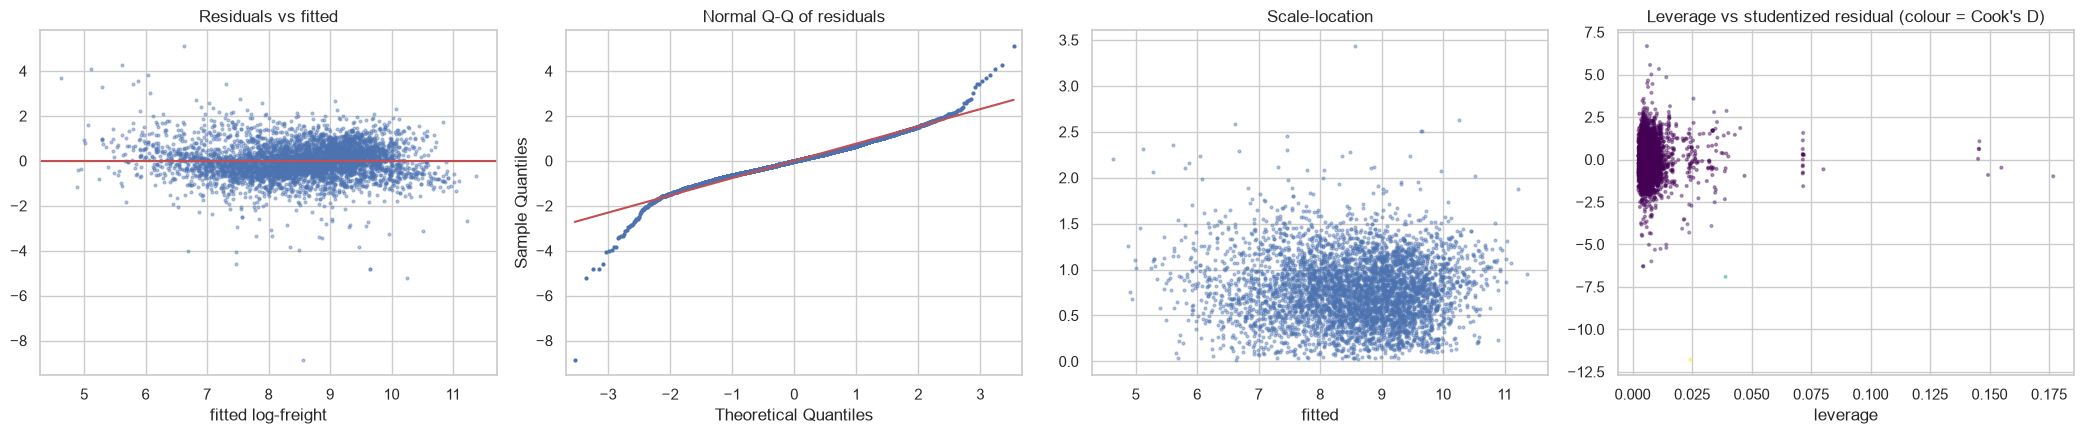

In [6]:
# Diagnostics
resid, fitted = ols.resid, ols.fittedvalues
infl = ols.get_influence(); cooks = infl.cooks_distance[0]; lev = infl.hat_matrix_diag; stud = infl.resid_studentized_external
bp = het_breuschpagan(resid, ols.model.exog)
sh = stats.shapiro(resid.sample(min(len(resid), 4000), random_state=SEED))
Xnum = sm.add_constant(dev[["log_weight", "log_ship_qty", "log_ship_value", "log_ship_lines", "year"]])
vif = pd.Series([variance_inflation_factor(Xnum.values, i) for i in range(1, Xnum.shape[1])], index=Xnum.columns[1:])
print("Breusch-Pagan: LM=%.1f, p=%.2e  -> heteroscedasticity %s (HC3 SEs used)" % (bp[0], bp[1], "present" if bp[1] < 0.05 else "not detected"))
print("Shapiro-Wilk on residuals (n<=4000): W=%.3f, p=%.2e | residual skew %.2f, excess kurtosis %.2f" % (sh[0], sh[1], stats.skew(resid), stats.kurtosis(resid)))
print("VIF of numeric predictors:", vif.round(2).to_dict())
print("Cook's D > 4/n: %d observations (%.1f%%) | max Cook's D %.3f | |studentized resid|>3: %d" % ((cooks > 4 / len(dev)).sum(), 100 * (cooks > 4 / len(dev)).mean(), cooks.max(), (np.abs(stud) > 3).sum()))
# robustness: refit without influential points
keep = cooks <= 4 / len(dev)
ols2 = smf.ols(formula, data=dev[keep]).fit()
print("Weight elasticity: full %.3f vs without high-Cook points %.3f" % (ols.params["log_weight"], ols2.params["log_weight"]))
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
ax[0].scatter(fitted, resid, s=4, alpha=.4); ax[0].axhline(0, c="r"); ax[0].set_title("Residuals vs fitted"); ax[0].set_xlabel("fitted log-freight")
sm.qqplot(resid, line="s", ax=ax[1], markersize=2); ax[1].set_title("Normal Q-Q of residuals")
ax[2].scatter(fitted, np.sqrt(np.abs(stud)), s=4, alpha=.4); ax[2].set_title("Scale-location"); ax[2].set_xlabel("fitted")
ax[3].scatter(lev, stud, s=4, alpha=.4, c=cooks, cmap="viridis"); ax[3].set_title("Leverage vs studentized residual (colour = Cook's D)"); ax[3].set_xlabel("leverage")
plt.tight_layout(); plt.savefig(OUT / "02_ols_diagnostics.png", dpi=130); plt.show()
pd.Series({"breusch_pagan_p": bp[1], "shapiro_p": sh[1], "resid_skew": stats.skew(resid), "resid_excess_kurtosis": stats.kurtosis(resid),
           "n_cooks_gt_4_over_n": int((cooks > 4 / len(dev)).sum()), "weight_elasticity_full": ols.params["log_weight"],
           "weight_elasticity_no_influential": ols2.params["log_weight"]}).round(5).to_csv(OUT / "ols_diagnostics.csv", header=["value"])

## 4. Predictive comparison - GroupKFold by shipment (development set)
Models: baselines (global mean of log-cost; **median USD/kg by shipment mode x weight** rule of thumb), OLS (same features, no formula), RidgeCV, LassoCV, ElasticNetCV (penalties chosen by *inner* CV), Random Forest, Gradient Boosting. Folds never split a shipment. Metrics on the log scale (R2, RMSE) and in USD after back-transformation (MAE, median absolute % error, WAPE = sum|error| / sum(actual)).

In [7]:
def pre(scale):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
inner = GroupKFold(5)
models = {
    "Baseline: mean log-cost": Pipeline([("p", pre(False)), ("m", DummyRegressor())]),
    "OLS": Pipeline([("p", pre(True)), ("m", LinearRegression())]),
    "Ridge": Pipeline([("p", pre(True)), ("m", RidgeCV(alphas=np.logspace(-2, 3, 30)))]),
    "Lasso": Pipeline([("p", pre(True)), ("m", LassoCV(cv=5, random_state=SEED, max_iter=20000))]),
    "ElasticNet": Pipeline([("p", pre(True)), ("m", ElasticNetCV(l1_ratio=[.2, .5, .8], cv=5, random_state=SEED, max_iter=20000))]),
    "Random Forest": Pipeline([("p", pre(False)), ("m", RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("p", pre(False)), ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED))]),
}
Xd, yd, gd = dev[NUM + CAT], dev.log_freight.values, dev.group.values
def score(y_log, p_log, y_usd=None):
    a, f = np.exp(y_log), np.exp(p_log)
    return {"R2 (log)": r2_score(y_log, p_log), "RMSE (log)": np.sqrt(mean_squared_error(y_log, p_log)), "MAE (USD)": mean_absolute_error(a, f),
            "MdAPE": np.median(np.abs(f - a) / a), "WAPE": np.abs(f - a).sum() / a.sum()}
gkf = GroupKFold(5)
oof, rows = {}, []
for n, m in models.items():
    oof[n] = cross_val_predict(m, Xd, yd, cv=gkf, groups=gd)
    rows.append({"Model": n, **score(yd, oof[n])})
# rule-of-thumb baseline: median USD/kg of training fold x weight
BASE = "Baseline: median USD/kg by mode x weight"
rt = np.zeros(len(dev)); mode_arr = dev["Shipment Mode_g"].values
for tr, va in gkf.split(Xd, yd, gd):
    med = pd.Series(dev.cost_per_kg.values[tr]).groupby(mode_arr[tr]).median()
    rt[va] = np.log(pd.Series(mode_arr[va]).map(med).fillna(np.median(dev.cost_per_kg.values[tr])).values * dev.weight.values[va])
oof[BASE] = rt
rows.append({"Model": BASE, **score(yd, rt)})
cvres = pd.DataFrame(rows).set_index("Model").sort_values("R2 (log)", ascending=False)
display(cvres.round(3)); cvres.round(4).to_csv(OUT / "cv_model_comparison.csv")
# CV spread per fold for the top model + paired comparison vs OLS
top = cvres.index[0]; print("Best by CV R2:", top)
fold_r2 = {n: [r2_score(yd[va], oof[n][va]) for _, va in gkf.split(Xd, yd, gd)] for n in ["OLS", "Ridge", "Random Forest", "Gradient Boosting"]}
print(pd.DataFrame(fold_r2).round(3).assign(fold=range(1, 6)).set_index("fold").agg(["mean", "std"]).round(3))

,R2 (log),RMSE (log),MAE (USD),MdAPE,WAPE
Model,,,,,
Gradient Boosting,0.759,0.629,3944.702,0.299,0.377
Random Forest,0.740,0.652,3981.046,0.295,0.381
OLS,0.633,0.776,5468.928,0.426,0.523
Ridge,0.633,0.776,5468.553,0.426,0.523
Lasso,0.629,0.780,5472.964,0.433,0.524
ElasticNet,0.629,0.780,5468.972,0.432,0.523
Baseline: mean log-cost,-0.000,1.281,8062.099,0.710,0.771
Baseline: median USD/kg by mode x weight,-0.059,1.318,13472.147,0.595,1.289


Best by CV R2: Gradient Boosting
        OLS  Ridge  Random Forest  Gradient Boosting
mean  0.633  0.633          0.740              0.759
std   0.028  0.028          0.023              0.028


## 5. Final chronological hold-out
Each model is refit on the whole development set and scored once on the newest 20% of shipments (a later period than anything seen in training, with different price levels - a harder, more realistic test than random CV).

,R2 (log),RMSE (log),MAE (USD),MdAPE,WAPE
Model,,,,,
Gradient Boosting,0.702,0.750,6119.797,0.362,0.443
Random Forest,0.695,0.759,6284.546,0.369,0.455
ElasticNet,0.629,0.837,6595.305,0.479,0.477
Lasso,0.627,0.840,6635.802,0.482,0.480
Ridge,0.626,0.841,6637.039,0.487,0.480
OLS,0.625,0.841,6639.111,0.488,0.481
Baseline: median USD/kg by mode x weight,0.392,1.071,13249.545,0.574,0.959
Baseline: mean log-cost,-0.021,1.389,11131.163,0.762,0.806


Best on hold-out: Gradient Boosting | R2 95% bootstrap CI [0.657, 0.740]
Test target mean (log) 8.75 vs dev 8.55; median USD/kg dev 7.65 vs test 6.04


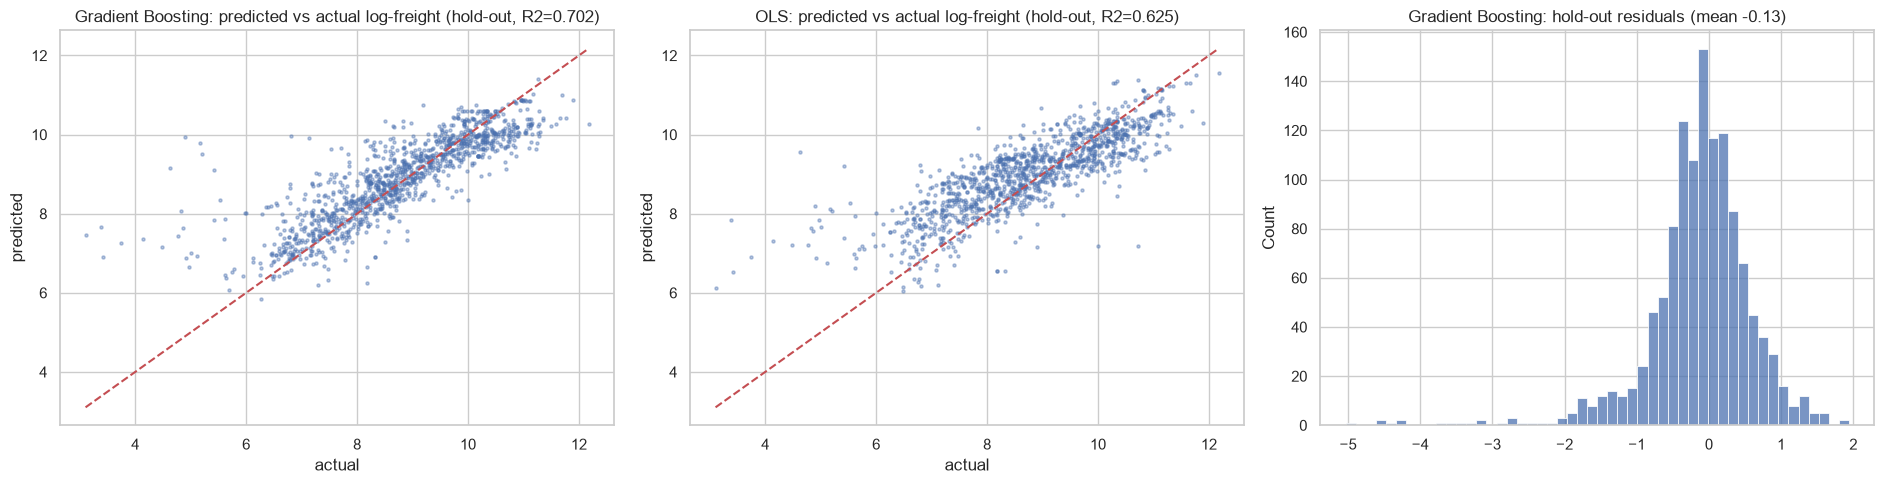

In [8]:
Xt, yt = test[NUM + CAT], test.log_freight.values
fitted, trows, tp = {}, [], {}
for n, m in models.items():
    fitted[n] = clone(m).fit(Xd, yd); tp[n] = fitted[n].predict(Xt); trows.append({"Model": n, **score(yt, tp[n])})
med_full = dev.groupby("Shipment Mode_g")["cost_per_kg"].median()
tp[BASE] = np.log(test["Shipment Mode_g"].map(med_full).fillna(dev.cost_per_kg.median()).values * test.weight.values)
trows.append({"Model": BASE, **score(yt, tp[BASE])})
testres = pd.DataFrame(trows).set_index("Model").sort_values("R2 (log)", ascending=False)
display(testres.round(3)); testres.round(4).to_csv(OUT / "test_model_comparison.csv")
# bootstrap CI for best model
best = testres.index[0]; rng = np.random.default_rng(SEED); r2s = []
for _ in range(500):
    i = rng.integers(0, len(yt), len(yt)); r2s.append(r2_score(yt[i], tp[best][i]))
print("Best on hold-out:", best, "| R2 95%% bootstrap CI [%.3f, %.3f]" % tuple(np.percentile(r2s, [2.5, 97.5])))
print("Test target mean (log) %.2f vs dev %.2f; median USD/kg dev %.2f vs test %.2f" % (yt.mean(), yd.mean(), dev.cost_per_kg.median(), test.cost_per_kg.median()))
o = test[["ID", "Country", "Shipment Mode", "sched", "weight", "freight"]].copy(); o["pred_freight_usd"] = np.exp(tp[best]); o["pred_model"] = best
o.to_csv(OUT / "test_set_predictions.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, n in zip(ax[:2], [best, "OLS"]):
    a.scatter(yt, tp[n], s=5, alpha=.4); lim = [min(yt.min(), tp[n].min()), max(yt.max(), tp[n].max())]; a.plot(lim, lim, "r--")
    a.set_title(f"{n}: predicted vs actual log-freight (hold-out, R2={r2_score(yt, tp[n]):.3f})"); a.set_xlabel("actual"); a.set_ylabel("predicted")
res_t = yt - tp[best]; sns.histplot(res_t, bins=50, ax=ax[2]); ax[2].set_title(f"{best}: hold-out residuals (mean {res_t.mean():.2f})")
plt.tight_layout(); plt.savefig(OUT / "03_holdout_predictions.png", dpi=130); plt.show()

Hold-out error by shipment mode:


,n,MdAPE,WAPE
Shipment Mode_g,,,
Air,721,0.298,0.340
Air Charter,102,0.488,0.563
Ocean,33,0.358,0.477
Truck,379,0.472,0.535


,feature,r2_drop,std
0,log_weight,0.4787,0.0202
2,log_ship_value,0.0896,0.0038
1,log_ship_qty,0.0841,0.0084
6,Country_g,0.0836,0.0100
5,Shipment Mode_g,0.0755,0.0060
7,Vendor INCO Term_g,0.0326,0.0031
3,log_ship_lines,0.0037,0.0006
8,Product Group_g,0.0030,0.0008
9,Vendor_g,0.0022,0.0025
4,year,0.0000,0.0000


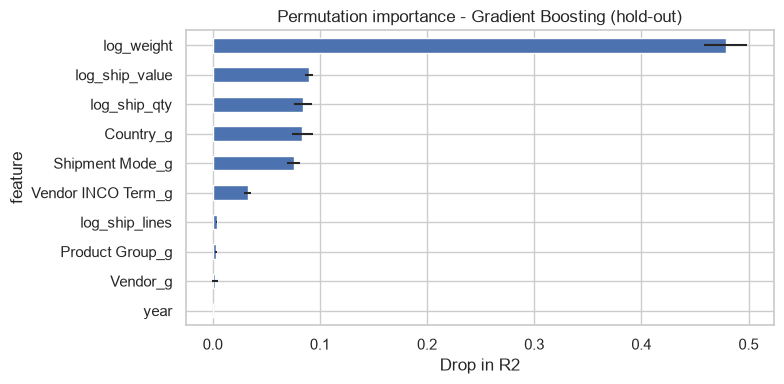

Lasso: alpha=0.0035, non-zero coefficients: 28 of 40


In [9]:
# Error by segment (hold-out, best model) - where is the model reliable?
seg = test.assign(pred=np.exp(tp[best]), act=test.freight)
seg["ape"] = (seg.pred - seg.act).abs() / seg.act
table = seg.groupby("Shipment Mode_g").agg(n=("act", "size"), MdAPE=("ape", "median"), WAPE=("ape", lambda s: (s * seg.loc[s.index, "act"]).sum() / seg.loc[s.index, "act"].sum()))
print("Hold-out error by shipment mode:"); display(table.round(3)); table.round(4).to_csv(OUT / "test_error_by_shipment_mode.csv")
pi = permutation_importance(fitted[best], Xt, yt, scoring="r2", n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": Xt.columns, "r2_drop": pi.importances_mean, "std": pi.importances_std}).sort_values("r2_drop", ascending=False)
display(imp.round(4)); imp.round(5).to_csv(OUT / "feature_importance_permutation.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4)); imp.iloc[::-1].plot.barh(x="feature", y="r2_drop", xerr="std", ax=ax, legend=False); ax.set_title(f"Permutation importance - {best} (hold-out)"); ax.set_xlabel("Drop in R2")
plt.tight_layout(); plt.savefig(OUT / "04_permutation_importance.png", dpi=130); plt.show()
lasso = fitted["Lasso"].named_steps["m"]; print("Lasso: alpha=%.4f, non-zero coefficients: %d of %d" % (lasso.alpha_, (lasso.coef_ != 0).sum(), len(lasso.coef_)))

## 6. Conclusions and limitations

**Setting:** 6,174 shipments with a recorded numeric freight cost and weight (60% of all lines; the rest are "included in commodity cost", "invoiced separately" or reference another line), chronological 80/20 split (dev 4,939 / hold-out 1,235), target = log(freight USD).

**Inferential model (OLS, development set, HC3-robust 95% CI)**
- R2 = 0.640 (adj. 0.638), residual std 0.77 log-units.
- **Weight elasticity 0.36 [0.31, 0.41]:** a 10% heavier shipment costs ~3.6% more - freight is strongly sub-linear in weight (fixed per-shipment costs dominate small loads). Without the 5% most influential points the elasticity is 0.445, so treat it as 0.35-0.45 rather than a precise value.
- At equal weight/quantity/value, **Truck is 34% cheaper than Air** (CI -39% to -28%), **Air Charter 33% dearer** (+16% to +52%), Ocean is not distinguishable from Air (+6%, p = 0.42). Shipment quantity (+0.07), value (+0.04, n.s.) and number of lines (+0.05, n.s.) add little once weight is known. Freight costs rose ~4.5% per year (CI +2.9% to +6.2%).
- **Assumption checks:** heteroscedasticity is present (Breusch-Pagan p ~ 1e-24) and residuals are heavy-tailed and left-skewed (excess kurtosis 7.1, Shapiro-Wilk p ~ 1e-35), which is why robust standard errors are used and why the CIs describe association rather than exact sampling intervals; VIFs are moderate (weight 6.0, quantity 5.9, value 3.9); 250 observations (5.1%) have Cook's D > 4/n and 50 have |studentized residual| > 3. A first draft that also included the fulfilment route produced a rank-deficient design matrix (perfectly collinear with the INCO term) - it was removed.

**Predictive comparison** (log-scale R2 and USD errors; "CV" = 5-fold GroupKFold by shipment on the development set; "Hold-out" = newest 20%)

| Model | CV R2 | Hold-out R2 | Hold-out MAE (USD) | Hold-out WAPE |
|---|---|---|---|---|
| Baseline: mean log-cost | 0.000 | -0.021 | 11,131 | 0.806 |
| Baseline: median USD/kg by mode x weight | -0.059 | 0.392 | 13,250 | 0.959 |
| OLS | 0.633 | 0.625 | 6,639 | 0.481 |
| Ridge / Lasso / ElasticNet | 0.629-0.633 | 0.626-0.629 | 6,595-6,637 | 0.477-0.480 |
| Random Forest | 0.740 | 0.695 | 6,285 | 0.455 |
| **Gradient Boosting** | **0.759** | **0.702** (95% CI 0.657-0.740) | **6,120** | **0.443** |

1. Non-linear models add ~0.07-0.12 R2 over the linear family (interactions such as mode x country x weight), but regularisation does nothing for a 40-column design with 4,900 rows (Ridge/Lasso/ElasticNet = OLS). In absolute terms the hold-out error of the best model is still ~44% of the freight bill (median absolute error 36%), so it is good for budgeting aggregates and for flagging implausible quotes, not for pricing a single shipment.
2. The simple "cost per kg" rule of thumb is a poor predictor (hold-out R2 0.39, WAPE 96%) because freight is sub-linear in weight - the log-log model captures this.
3. Hold-out performance is below CV (0.70 vs 0.76) because of drift: the median USD/kg fell from 7.65 (dev) to 6.04 (hold-out). Error is highest for Air Charter (WAPE 56%) and Truck (54%), lowest for scheduled Air (34%).
4. Permutation importance (hold-out, R2 drop): weight 0.48, then value 0.09, quantity 0.08, country 0.08, shipment mode 0.08, INCO term 0.03.

**Limitations**
- **Selection bias:** only shipments with an explicit numeric freight cost are modelled; "freight included in commodity cost" (DDP-type) and "invoiced separately" shipments are excluded, so conclusions do not apply to them.
- Weight is a shipment-level quantity that is itself only known once the shipment is consolidated; using it as an input assumes a quote at that point of planning.
- Shipment quantity/value are summed over lines sharing an ASN/DN number; a few shipments with partial records may be mis-aggregated.
- Price levels drift over 2006-2015 (and exchange/fuel effects are not modelled); no inflation adjustment other than a linear year term.
- Ridge/Lasso/ElasticNet penalties were selected by internal random 5-fold CV (not grouped; harmless here because each row is a distinct shipment); Random Forest and Gradient Boosting use fixed hyper-parameters, so the tree-model scores are, if anything, conservative. Predictions are back-transformed with `exp()` without a smearing correction, so USD predictions estimate the conditional median and under-estimate the mean.